# 01 - Análise exploratória (EDA) — Etapa 1: geração hidráulica e GSF

**Objetivo:** entender o que determina o GH_band (geração hidráulica do MRE usada no GSF da bandeira), usando as
variáveis **previstas pelo ONS no PMO** de cada mês (DECOMP rv0), o mesmo conjunto de informação que gera o GH_band.

**Dados:** jan/2023 a out/2026 (46 meses) — `relato.rv0` e `ena.pdf` (ONS), boletins InfoBandeira (CCEE) e patamares (CCEE);
`renovaveis.csv` em 2026 para separar eólica e solar. Memorial de cálculo em `docs/metodologia.md`, seção 3.5.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import features, graficos, load

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Base mensal

Monta a base a partir dos arquivos brutos e salva em `data/processed/base_mensal.parquet`.

Transições no `relato.rv0` tratadas na leitura: MMGD (linhas `*gd`) só a partir de mai/2023 (antes a carga já vinha
líquida dela); eólica e solar centralizadas nas pequenas usinas até set/2025 e no `Geol` (somadas) a partir de out/2025.

In [2]:
base = features.base_mensal()
base.to_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.shape

(46, 53)

## 2. Validação do alvo contra os boletins

GH_band calculado a partir do `relato.rv0` contra o publicado pela CCEE; cor pela regra (ábaco) com o GSF e o PLD gatilho
do boletim. O PLD gatilho vem do deck da CCEE, **não** do CMO do ONS. Em 7 boletins a cor está em imagem (sem texto).

In [3]:
val = base[["gh_band", "gh_band_boletim", "gsf_calc", "gsf_band_boletim", "pld_gatilho_boletim",
            "gfom_boletim", "cor_boletim", "cor_regra"]].copy()
val["dif_gh_band"] = val.gh_band - val.gh_band_boletim
print("GSF igual ao boletim:", (val.gsf_calc == val.gsf_band_boletim).sum(), "/", len(val))
print("cor da regra = publicada:", (val.cor_regra == val.cor_boletim).sum(), "/", val.cor_boletim.notna().sum())
val[val.dif_gh_band.abs() > 5]

GSF igual ao boletim: 46 / 46
cor da regra = publicada: 39 / 39


,gh_band,gh_band_boletim,gsf_calc,gsf_band_boletim,pld_gatilho_boletim,gfom_boletim,cor_boletim,cor_regra,dif_gh_band
mes,,,,,,,,,
2023-10-01,"46,290.91","46,284.00",0.87,0.87,69.04,NaN,NaN,Verde,6.91
2024-11-01,"43,584.95","43,575.00",0.82,0.82,286.80,0.00,Amarela,Amarela,9.95
2025-04-01,"49,604.58","50,049.00",0.94,0.94,208.03,0.00,Verde,Verde,-444.42
2025-06-01,"39,960.96","39,705.00",0.75,0.75,310.35,265.00,NaN,Vermelha 1,255.96


Desvios maiores que 5 MWmed: **jun/2025** (+256) é o GFOM do mês (265 MWmed; o GH enviado pelo ONS à CCEE já desconta a
térmica por segurança energética); **abr/2025** (−444) ainda sem explicação (Q17); out/2023 e nov/2024 são pequenos.
Nenhum muda o GSF.

## 3. Fechamento do balanço

`carga líquida + bombeamento = hidráulica (SIN) + renováveis + térmica (inclui antecipada) + PCH + PCT`.

In [4]:
print("maior |resíduo| (MWmed):", base.residuo.abs().max().round(3))
base[["carga_liquida", "mmgd", "renovaveis", "termica", "nuclear", "pch", "pct", "gh_sin", "bombeamento", "residuo"]]

maior |resíduo| (MWmed): 0.121


,carga_liquida,mmgd,renovaveis,termica,nuclear,pch,pct,gh_sin,bombeamento,residuo
mes,,,,,,,,,,
2023-01-01,"73,325.02",0.00,"10,419.41","3,909.15","1,990.00","3,823.79","1,978.38","53,246.05",51.80,0.04
2023-02-01,"73,219.58",0.00,"8,296.85","3,928.86","1,990.00","4,013.04","1,979.78","55,059.80",58.72,-0.03
2023-03-01,"75,610.29",0.00,"8,069.48","3,920.56","1,990.00","3,968.13","2,387.21","57,316.34",51.47,0.03
2023-04-01,"72,891.41",0.00,"9,507.93","4,193.70","1,990.00","3,508.07","4,182.33","51,570.92",71.56,0.01
2023-05-01,"69,835.44","2,908.95","11,406.78","4,111.56","1,990.00","3,342.96","5,108.23","45,927.06",61.15,0.01
2023-06-01,"67,782.61","3,041.61","13,209.73","4,619.48","1,990.00","3,275.36","5,433.60","41,287.91",43.48,0.01
2023-07-01,"67,690.29","3,243.91","15,443.13","4,559.71","1,990.00","2,799.12","5,671.88","39,262.56",46.10,-0.00
2023-08-01,"69,174.38","3,918.84","17,471.79","4,354.02","1,990.00","2,568.24","5,551.38","39,272.55",43.59,-0.00
2023-09-01,"70,733.81","3,821.07","17,889.06","4,191.91","1,720.00","2,491.17","5,353.61","40,853.23",45.14,-0.02


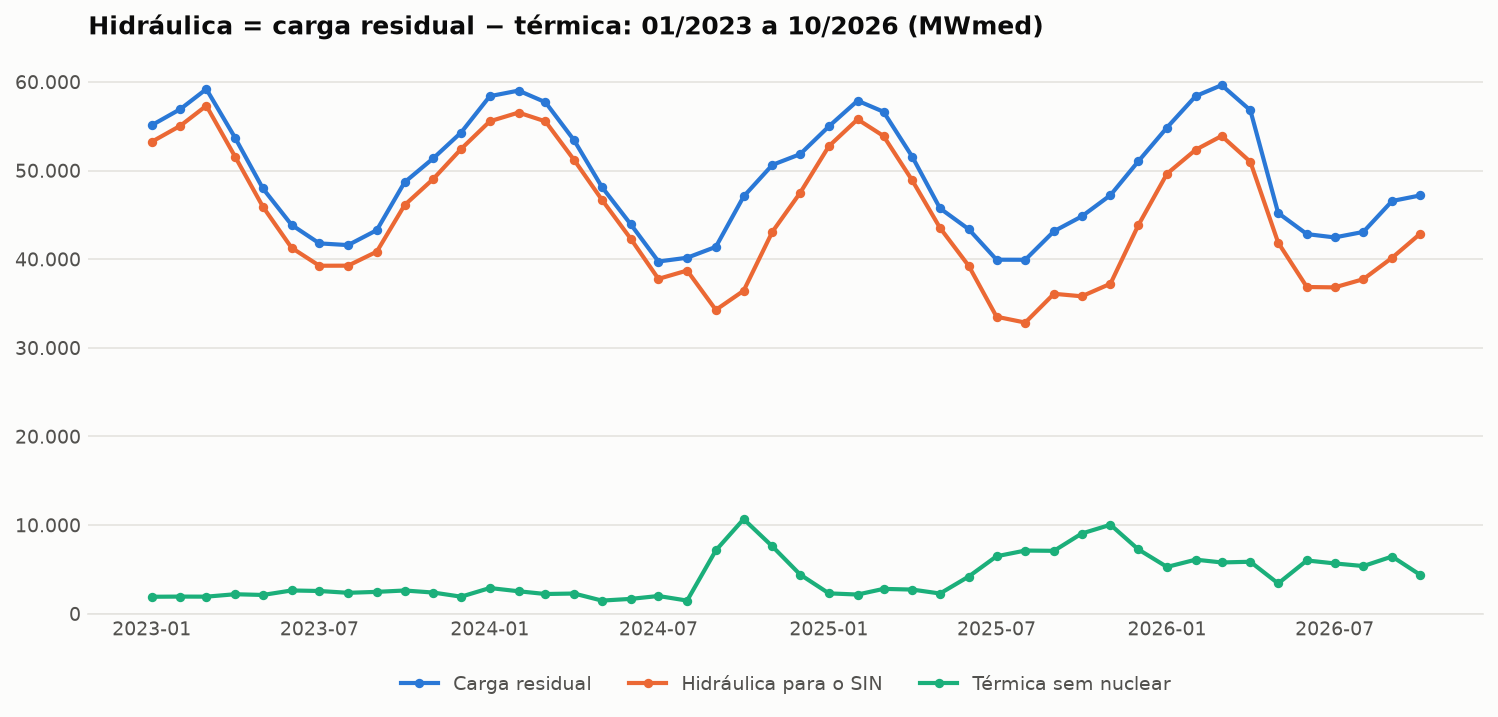

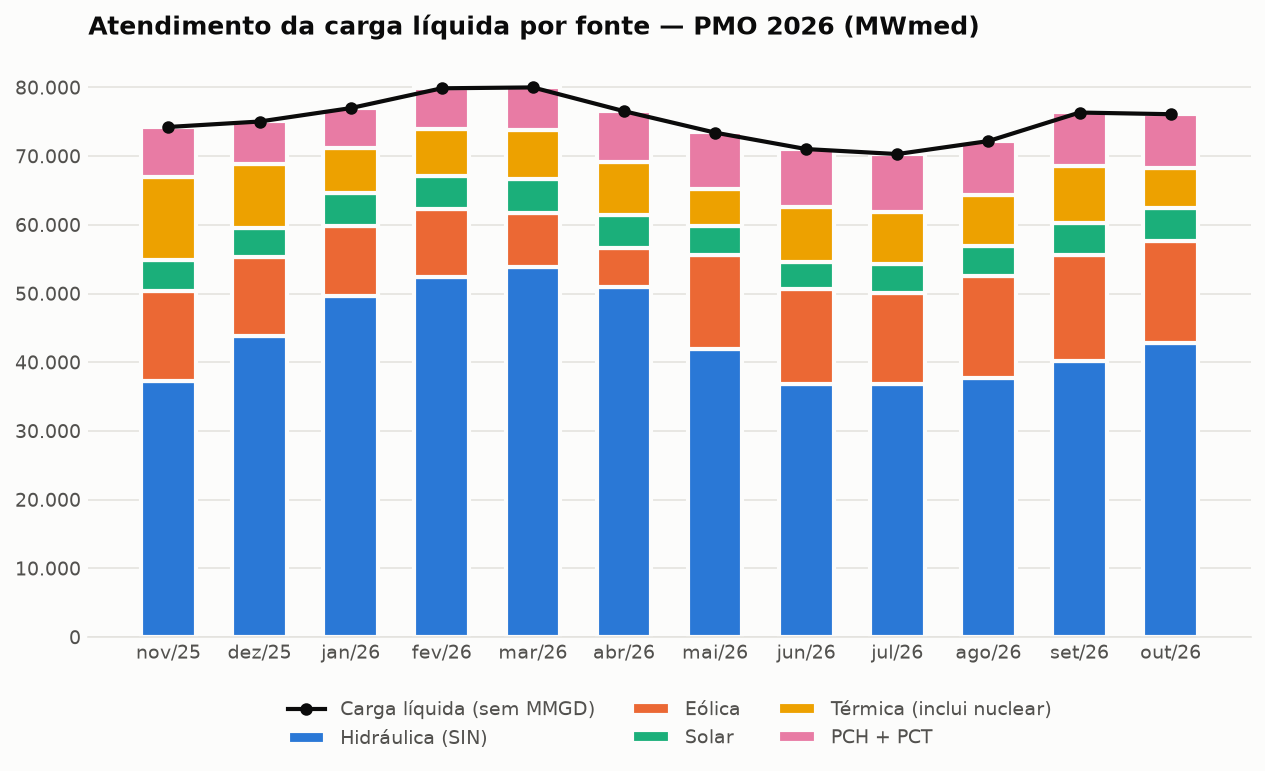

In [5]:
display(Image(graficos.serie_historica(base)))
display(Image(graficos.balanco_empilhado(base.tail(12), nome="01_balanco_mensal.png")))

## 4. GH_band contra as variáveis candidatas (níveis)

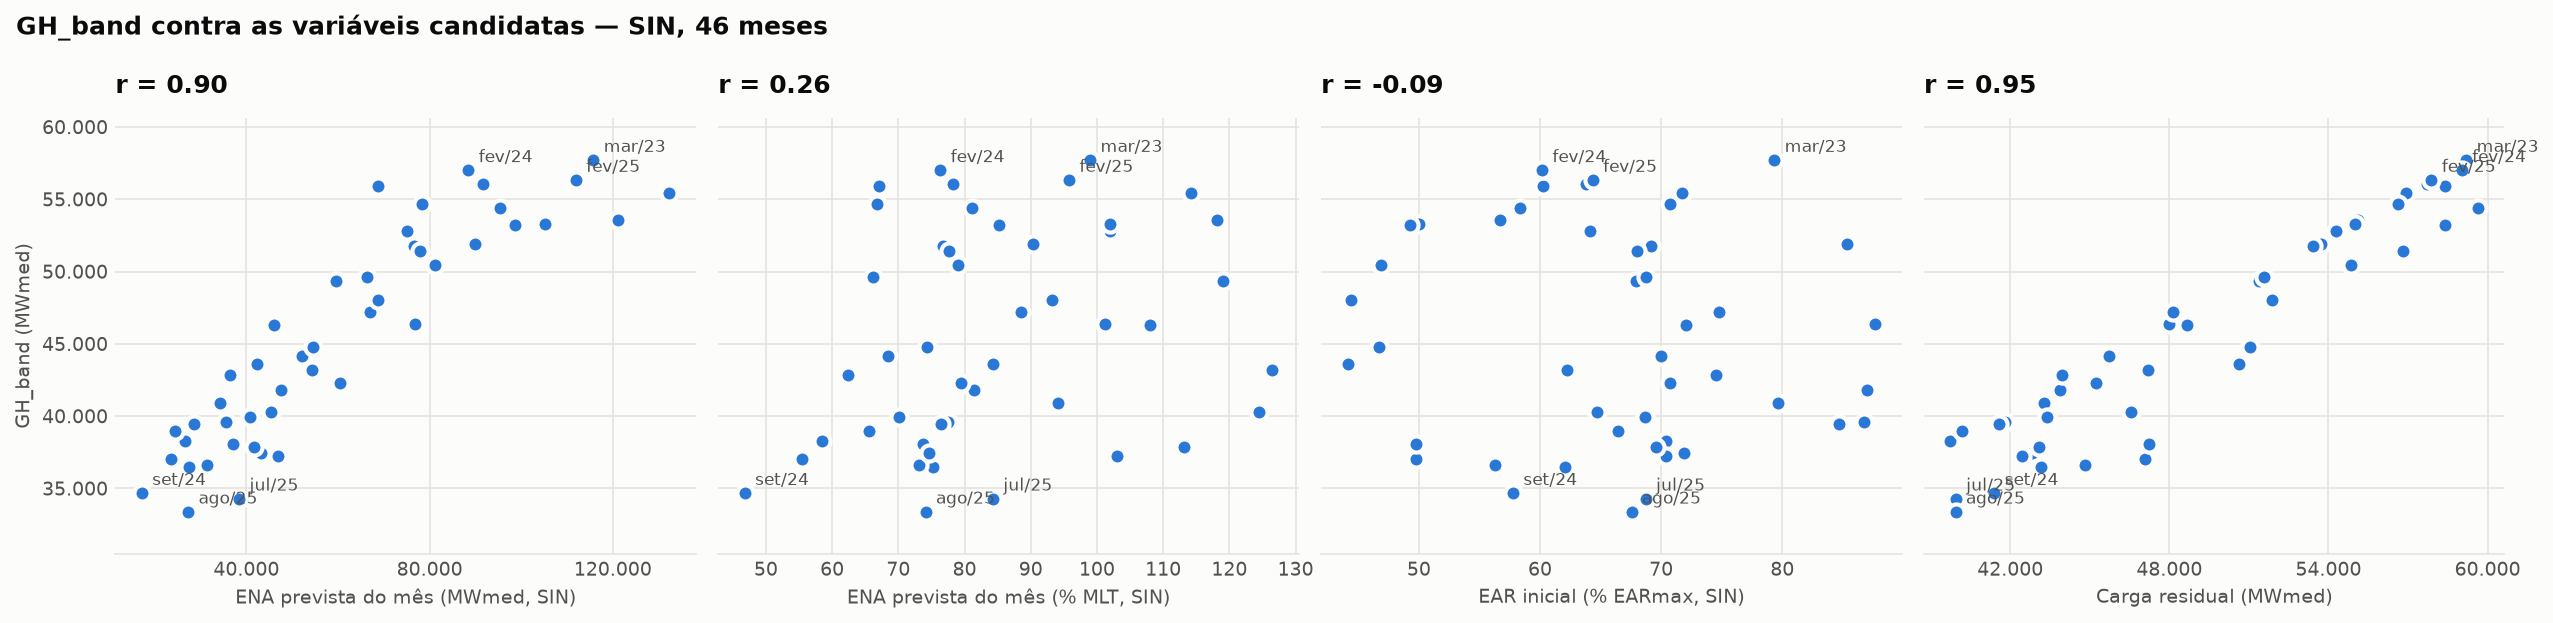

In [6]:
display(Image(graficos.dispersoes_gh(base)))

In [7]:
def ols(y, colunas):
    X = np.column_stack([np.ones(len(y))] + [base[c] for c in colunas])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ coef
    return {"R²": 1 - (res**2).sum() / ((y - y.mean())**2).sum(), "desvio do resíduo": res.std(),
            "coeficientes": np.round(coef[1:], 3)}

modelos = [["carga_residual"], ["carga_residual", "termica_sem_nuclear"], ["ena_sin"], ["ena_mlt_sin"],
           ["carga_residual", "ena_mlt_sin"], ["carga_residual", "ena_mlt_sin", "ear_ini_sin"]]
pd.DataFrame({" + ".join(m): ols(base.gh_band, m) for m in modelos}).T

,R²,desvio do resíduo,coeficientes
carga_residual,0.90,"2,320.46",[1.093]
carga_residual + termica_sem_nuclear,1.00,187.31,"[1.009, -0.962]"
ena_sin,0.81,"3,195.86",[0.227]
ena_mlt_sin,0.07,"7,129.21",[102.63]
carga_residual + ena_mlt_sin,0.90,"2,294.41","[1.08, 18.902]"
carga_residual + ena_mlt_sin + ear_ini_sin,0.95,"1,726.96","[1.166, 4.422, 139.497]"


## 5. ENA × geração hidráulica (SIN)

Em **níveis**, a ENA em MWmed tem correlação alta com o GH_band, mas é sazonalidade compartilhada (período úmido = muita
água, pouco vento, carga alta). Para separar, comparamos **anomalias**: o desvio de cada mês em relação à média do mesmo
mês do ano nos outros anos.

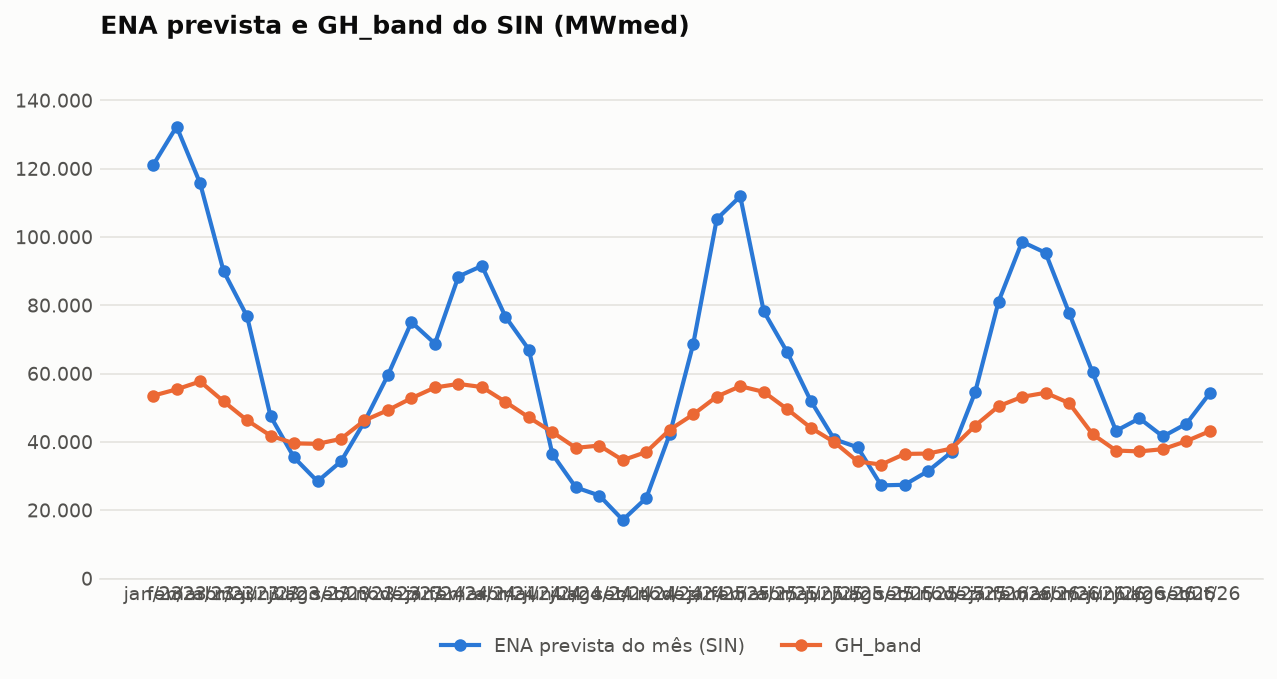

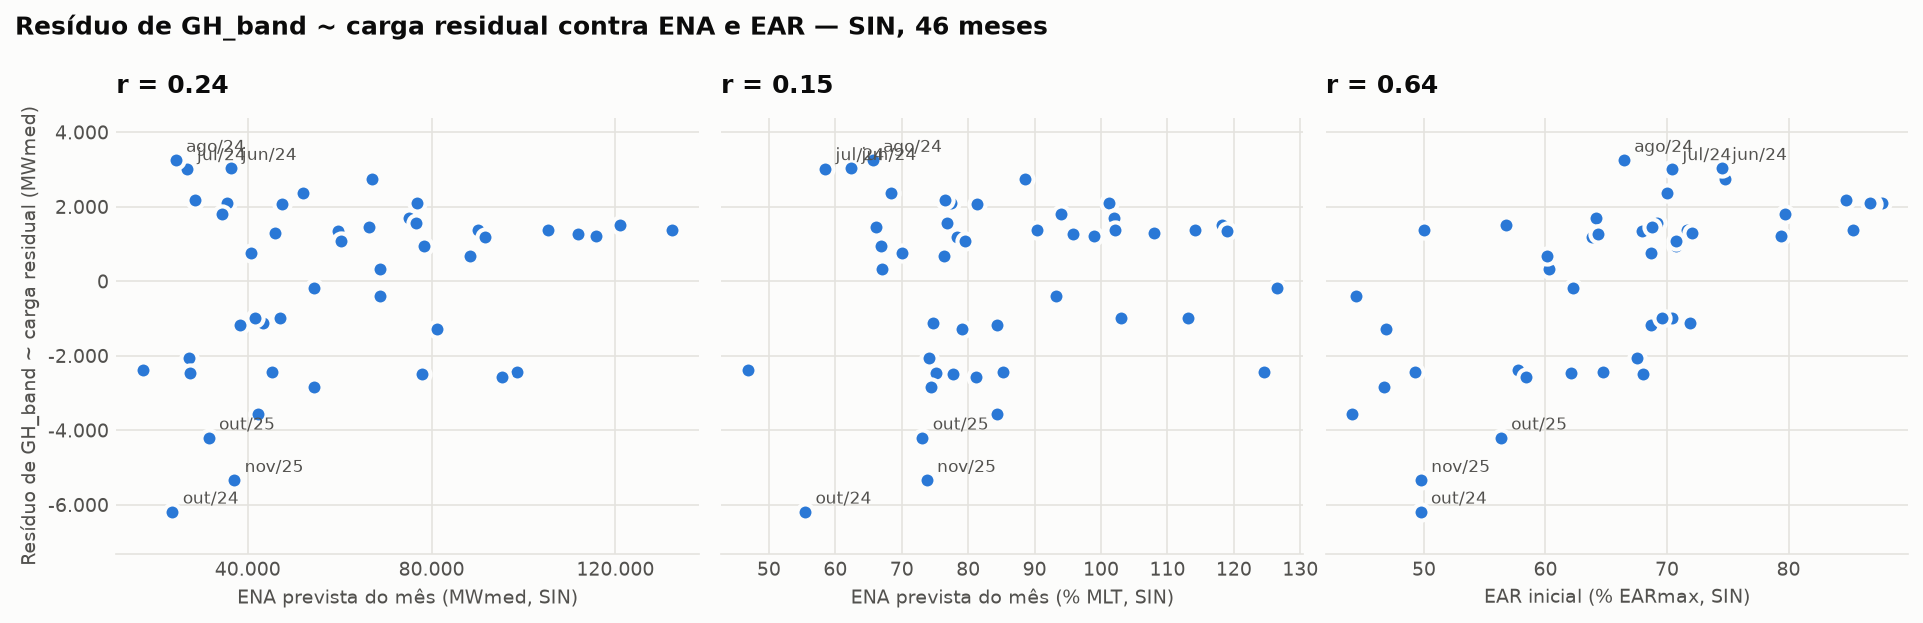

In [8]:
display(Image(graficos.gh_vs_ena(base)))
coef = np.polyfit(base.carga_residual, base.gh_band, 1)
residuo_gh = base.gh_band - np.polyval(coef, base.carga_residual)
display(Image(graficos.residuo_vs_ena(base, residuo_gh)))

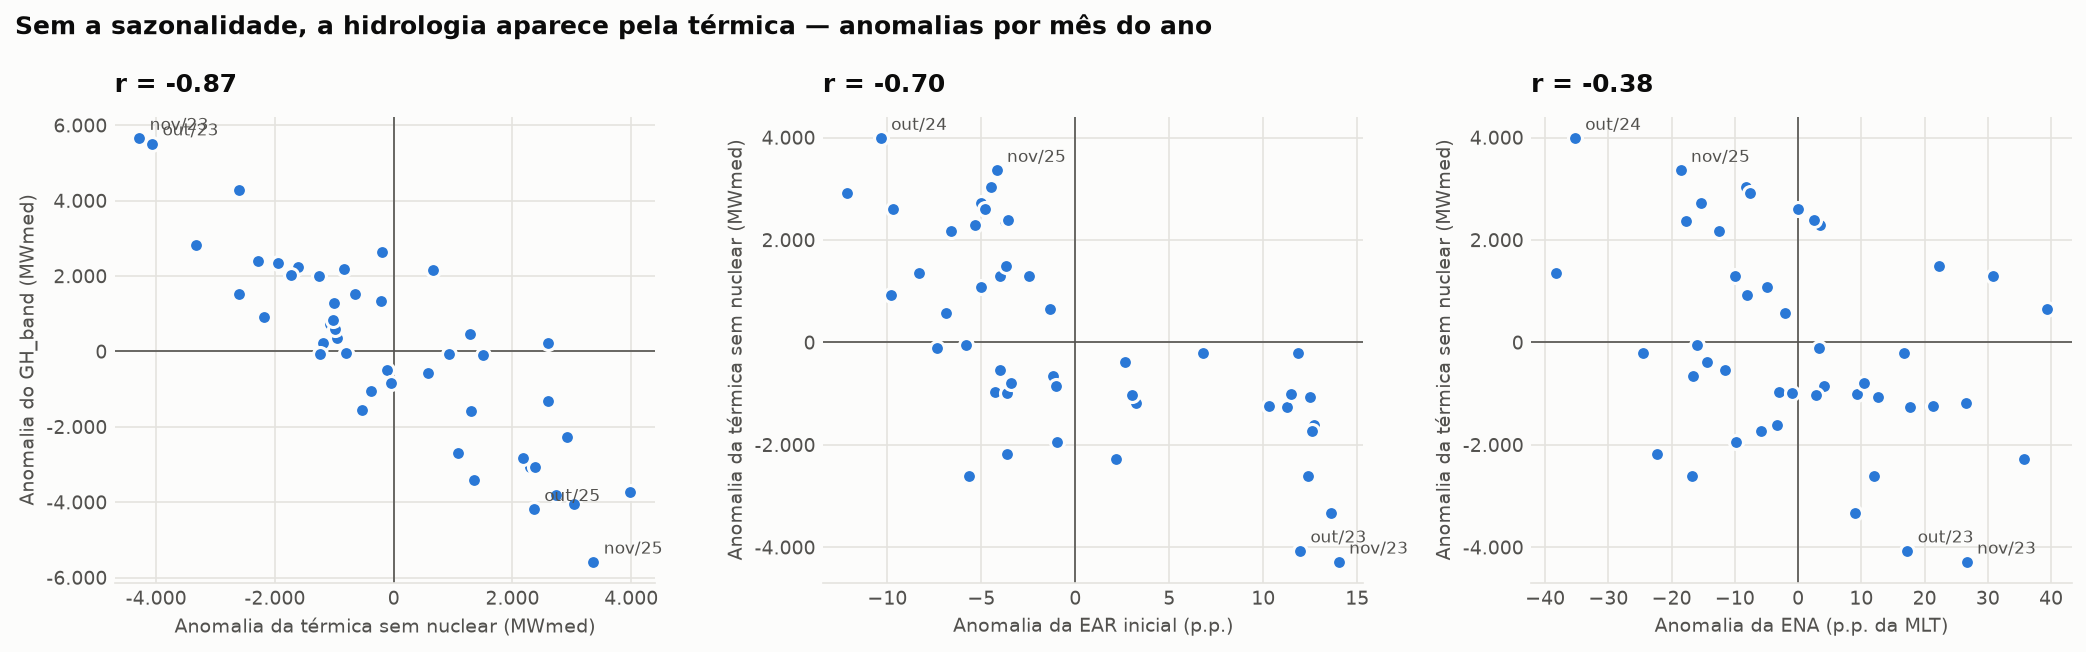

,anomalia × GH_band,anomalia × térmica s/ nuclear
gh_band,1.00,-0.87
carga_residual,0.67,-0.20
termica_sem_nuclear,-0.87,1.00
ena_sin,0.41,-0.36
ena_mlt_sin,0.52,-0.38
ear_ini_sin,0.69,-0.70


In [9]:
display(Image(graficos.anomalias(base)))
cols = ["gh_band", "carga_residual", "termica_sem_nuclear", "ena_sin", "ena_mlt_sin", "ear_ini_sin"]
an = base[cols] - base[cols].groupby(base.index.month).transform("mean")
pd.DataFrame({"anomalia × GH_band": an.corrwith(an.gh_band),
              "anomalia × térmica s/ nuclear": an.corrwith(an.termica_sem_nuclear)})

## 6. Térmica por ano e meses de estresse

Térmica = inflexível (GTmin, inclui nuclear) + mérito do mês + antecipada (`GterAT`: GNL despachado por mérito com
antecedência).

In [10]:
cols = ["gh_band", "carga_residual", "termica_sem_nuclear", "termica_merito", "termica_antecipada",
        "ena_mlt_sin", "ear_ini_sin", "gsf_band_boletim"]
base.groupby(base.index.year)[cols].agg(["mean", "min", "max"]).T

mes                           2023      2024      2025      2026
gh_band             mean 47,919.16 45,945.72 43,459.92 44,774.32
                    min  39,435.91 34,659.95 33,372.05 37,226.09
                    max  57,697.78 56,991.27 56,317.36 54,396.98
carga_residual      mean 49,819.63 49,293.84 48,027.94 49,703.94
                    min  41,592.97 39,741.70 39,937.05 42,458.44
                    max  59,195.46 59,023.64 57,882.32 59,639.12
termica_sem_nuclear mean  2,258.02  3,872.71  5,298.13  5,441.11
                    min   1,919.15  1,486.56  2,168.97  3,418.38
                    max   2,629.48 10,679.78 10,041.87  6,457.84
termica_merito      mean      0.00  1,468.28  2,129.98  1,995.79
                    min      -0.00      0.00      8.43    484.25
                    max       0.00  8,047.37  4,147.35  3,778.37
termica_antecipada  mean     37.43    222.20    476.44    374.44
                    min       0.00      0.00      0.00      0.00
                    max     225.81  1,705.42  2,134.62  1,845.44
ena_mlt_sin         mean     98.43     71.09     77.01     94.43
                    min      76.48     46.78     66.16     74.64
                    max     118.99     93.17    102.03    126.47
ear_ini_sin         mean     76.91     61.29     61.97     63.20
                    min      56.72     44.11     46.75     46.88
                    max      87.66     74.75     70.72     71.90
gsf_band_boletim    mean      0.90      0.86      0.82      0.85
                    min       0.74      0.65      0.63      0.70
                    max       1.09      1.07      1.06      1.03

In [11]:
base.sort_values("termica_sem_nuclear", ascending=False)[
    ["termica_sem_nuclear", "termica_merito", "ear_ini_sin", "ena_mlt_sin", "gsf_band_boletim", "cor_regra"]].head(8)

,termica_sem_nuclear,termica_merito,ear_ini_sin,ena_mlt_sin,gsf_band_boletim,cor_regra
mes,,,,,,
2024-10-01,"10,679.78","8,047.37",49.72,55.46,0.69,Vermelha 2
2025-11-01,"10,041.87","4,147.35",49.74,73.75,0.72,Vermelha 1
2025-10-01,"9,053.69","3,186.11",56.32,73.10,0.69,Vermelha 1
2024-11-01,"7,604.45","3,753.46",44.11,84.27,0.82,Amarela
2025-12-01,"7,266.09","4,004.25",46.75,74.40,0.84,Amarela
2024-09-01,"7,153.68","5,076.53",57.76,46.78,0.65,Vermelha 1
2025-08-01,"7,131.99","2,776.33",67.56,74.12,0.63,Vermelha 2
2025-09-01,"7,099.91","3,011.78",62.07,75.19,0.69,Vermelha 2


## 7. Conclusões (46 meses, jan/2023–out/2026)

1. **Alvo e balanço validados no histórico:** GSF idêntico ao boletim em 46/46 meses, cor da regra igual à publicada em
   39/39 (os outros 7 têm a cor em imagem), balanço fechando a menos de 0,13 MWmed em todos os meses.
2. **O GH_band é praticamente uma identidade:** GH_band ≈ 1,01 × carga residual − 0,96 × térmica sem nuclear
   (R² = 0,999, desvio de 187 MWmed). Só a carga residual explica 90% (R² = 0,90; desvio de 2,3 mil MWmed);
   o resto é a térmica.
3. **A ENA não explica o GH_band diretamente.** Em níveis, a correlação com a ENA em MWmed (0,90) é sazonalidade; em
   % da MLT é 0,26. Acrescentar a ENA à carga residual quase não muda o ajuste (R² 0,901 → 0,904).
4. **Mas a hidrologia importa, pela térmica.** Sem a sazonalidade (anomalias), a térmica explica o GH_band (r = −0,87)
   e responde ao **armazenamento** (r = −0,70 com a EAR inicial) mais do que à ENA do mês (r = −0,38). Com EAR + ENA,
   o ajuste do GH_band sobe para R² = 0,945.
5. **É nos anos secos que isso decide a cor:** em set–out/2024 (ENA 47–56% da MLT, EAR ~50–58%) e no 2º semestre de
   2025, a térmica sem nuclear foi a 7–10,7 mil MWmed (contra ~2,3 mil em 2023), derrubando o GSF para 0,63–0,69 e
   levando a vermelha 1 e 2. Uma térmica 5 mil MWmed acima do normal tira ~0,1 do GSF.
6. **Caminho para o modelo:** GH_band = carga residual (das projeções) − térmica sem nuclear, onde a **térmica** é a
   parte a modelar com a hidrologia: armazenamento (principal), ENA prevista (ECMWF) e despachos já comprometidos
   (GNL antecipado). Para o horizonte de 6 meses, será preciso projetar a trajetória do armazenamento.